# Changing Task Count

Three questions, one problem:
1. With spare capacity, does the learner keep features that are temporarily unused?
2. With too little capacity, does it use the capacity it has well?
3. Does it keep adapting as the number of tasks changes?

**Problem.** Three fixed teachers map 21 random ±1 inputs through 10 LTUs to 10 linear outputs, with ±1 weights. A teacher LTU fires when its weighted input sum exceeds 4, on about 20% of inputs. Targets have Gaussian noise of standard deviation 1. Training runs five phases of 500k steps with 3, 2, 1, 2 and 3 active teachers: teacher 3 leaves first and returns last. The active teacher switches every 10k steps, and no task ID is given. The learner has 21 inputs → 20 LTUs → 10 linear outputs, capacity for two teachers.

**Methods.** Five seeds, shared by all methods.
- SGD with step sizes $2^{-9}$ to $2^{-5}$.
- Autostep: centered hidden units, small initial hidden weights, meta step 0.02, initial ln(α) = −8.
- Autostep + standardization: hidden units are also divided by their running standard deviation (variance floored at 0.01).
- Baseline: all 30 true teacher LTUs as frozen hidden units; only the readout learns (Autostep + standardization).

The learning curves show the first 40k steps, 40k steps on each side of every phase change, and the last 40k steps. Dashed lines mark the phase changes, and the number above each block is the active teacher. After the step-size sweep, SGD is shown at the step size with the lowest whole-run RMSE.

Hidden units are measured on 1000 fixed random inputs. A unit is dead if it fires on fewer than 1% or more than 99% of them. Units are grouped by the teacher whose LTU they best match (largest |correlation| of firing) when the 1-task phase starts, and the correlation plot shows the |correlation| of each unit's firing with its own firing at that time. Curves are means over seeds; correlations are medians over units and seeds.

In [1]:
from functools import partial
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problem
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
N_TASKS = 3
THRESHOLD = 4  # teacher LTUs fire on about 20% of inputs
N_HIDDEN = 2 * WIDTH  # capacity for two teachers

# Schedule
ACTIVE = (3, 2, 1, 2, 3)  # active teachers in each phase
PHASE_STEPS = 500_000
PERIOD = 10_000  # steps before switching to the next active teacher
STEPS = len(ACTIVE) * PHASE_STEPS
WINDOW = 1000
SIDE = 40_000  # steps shown on each side of a phase change, and at the start and end

# Methods
SGD_EXPONENTS = (-9, -8, -7, -6, -5)
INIT_RATE, META_RATE, EMA_RATE = np.exp(-8.), 0.02, 1e-3
VAR_FLOOR = .01
N_SEEDS = 5
PROBE = jnp.asarray(np.random.default_rng(0).choice([-1., 1.], (1000, N_INPUTS)), dtype=jnp.float32)

In [3]:
def init_teacher(key):
    input_key, output_key = jax.random.split(key)
    w = jax.random.rademacher(input_key, (WIDTH, N_INPUTS), dtype=jnp.float32)
    v = jax.random.rademacher(output_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    return w, v


def target(teacher, x):
    w, v = teacher
    return v @ (w @ x > THRESHOLD).astype(jnp.float32)


def teachers_for(seed):
    teacher_key = jax.random.split(jax.random.PRNGKey(seed), 3)[0]
    return jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')


class Learner(NamedTuple):
    weights: tuple  # hidden (unit, input + bias), readout (output, unit + bias)
    opt: object
    mean: jax.Array  # running mean of each hidden unit
    slope: jax.Array  # running mean of sigma'(z) x
    cov: jax.Array  # running covariance of the unit with sigma'(z) x


def init_learner(key, method, hidden):
    width = len(hidden) if hidden is not None else N_HIDDEN
    bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / N_INPUTS)
    if hidden is None:
        hidden = jax.random.uniform(key, (width, N_INPUTS + 1), minval=-bound, maxval=bound).at[:, -1].set(0.)
    weights = (hidden, jnp.zeros((N_OUTPUTS, width + 1)))
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   jnp.full(width, .5), jnp.zeros_like(hidden).at[:, -1].set(.25), jnp.zeros_like(hidden))


def forward(weights, x, learner, method, standardize):
    source = jnp.append(x, 1.)
    z = weights[0] @ source
    h = ltu(z)
    mean, slope, cov = learner.mean, learner.slope, learner.cov
    if method == 'Autostep':
        # Centering, with the backward pass accounting for how the mean changes with the input weights.
        mean = mean + EMA_RATE * (jax.lax.stop_gradient(h) - mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))[:, None] * source
        slope = slope + EMA_RATE * (derivative - slope)
        correction = jnp.sum(slope * weights[0], axis=1)
        centered = jax.lax.stop_gradient(h - mean)
        h = h - mean + (jax.lax.stop_gradient(correction) - correction)
        # Standardization: also divide by the running standard deviation, accounting for how it changes.
        cov = cov + EMA_RATE * (centered[:, None] * (derivative - slope) - cov)
        var = mean * (1 - mean)
        change = jnp.sum(cov * weights[0], axis=1)
        floored = jnp.maximum(var, VAR_FLOOR)
        standardized = h - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / floored, 0.)
        h = jnp.where(standardize, standardized / jnp.sqrt(floored), h)
    hidden = jnp.append(h, 1.)
    return weights[1] @ hidden, ((source[None], hidden[None]), mean, slope, cov)


def update(learner, x, y, method, rate, standardize, frozen):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, method, standardize)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, mean, slope, cov)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -rate * g, grads), None
    if frozen:
        updates = (jnp.zeros_like(updates[0]), updates[1])
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, mean, slope, cov), 2 * loss_value / N_OUTPUTS

In [5]:
def train(seed, rate, standardize, method, baseline):
    learner_key, rng = jax.random.split(jax.random.PRNGKey(seed), 3)[1:]
    teachers = teachers_for(seed)
    # Baseline: every teacher LTU as a frozen hidden unit.
    true = jnp.append(teachers[0].reshape(-1, N_INPUTS), jnp.full((N_TASKS * WIDTH, 1), -THRESHOLD), axis=1)
    learner = init_learner(learner_key, method, true if baseline else None)
    active = jnp.repeat(jnp.array(ACTIVE), PHASE_STEPS // PERIOD)

    def block(carry, block_id):
        teacher = jax.tree.map(lambda w: w[block_id % active[block_id]], teachers)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
            learner, mse = update(learner, x, y, method, rate, standardize, baseline)
            return (learner, rng), mse

        def record(carry, _):
            carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
            return carry, (mse.mean(), carry[0].weights[0])
        return jax.lax.scan(record, carry, length=PERIOD // WINDOW)

    _, records = jax.lax.scan(block, (learner, rng), jnp.arange(STEPS // PERIOD))
    return jax.tree.map(lambda r: r.reshape(-1, *r.shape[2:]), records)  # window-mean MSE, hidden weights at window ends


@partial(jax.jit, static_argnames=('method', 'baseline'))
def run(method, rates, standardize, baseline=False):
    seeds = jax.vmap(partial(train, method=method, baseline=baseline), in_axes=(0, None, None))
    return jax.vmap(seeds, in_axes=(None, 0, 0))(jnp.arange(N_SEEDS), rates, standardize)

In [6]:
n = len(SGD_EXPONENTS)
sgd = run('SGD', 2. ** jnp.array(SGD_EXPONENTS), jnp.zeros(n, bool))
autostep = run('Autostep', jnp.zeros(2), jnp.array([False, True]))
baseline = run('Autostep', jnp.zeros(1), jnp.array([True]), baseline=True)
mse = np.concatenate([sgd[0], autostep[0], baseline[0]])  # (method, seed, window)
hidden = np.concatenate([sgd[1], autostep[1]])  # (method, seed, window, unit, input + bias)
LABELS = [rf'SGD $2^{{{p}}}$' for p in SGD_EXPONENTS] + ['Autostep', 'Autostep + standardization', 'Baseline: all true features']
COLORS = [*plt.cm.Reds(np.linspace(.4, .9, n)), 'tab:cyan', 'tab:blue', 'gray']
best = int(np.argmin(np.sqrt(mse[:n].mean(2)).mean(1)))  # SGD step size with the lowest whole-run RMSE
x = np.arange(1, STEPS // WINDOW + 1) * WINDOW

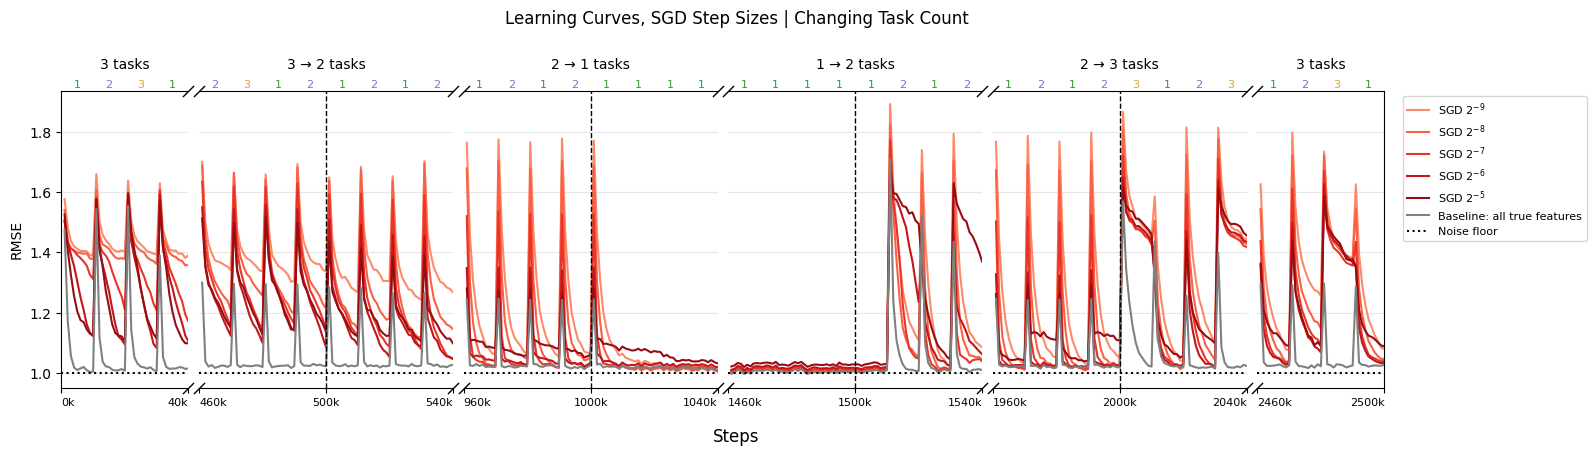

In [7]:
TASK_COLORS = ('tab:green', 'tab:purple', 'goldenrod')
SECTIONS = [(0, SIDE), *((t - SIDE, t + SIDE) for t in range(PHASE_STEPS, STEPS, PHASE_STEPS)), (STEPS - SIDE, STEPS)]
active = np.repeat(ACTIVE, PHASE_STEPS // PERIOD)
tasks = np.arange(len(active)) % active  # the teacher of every block


def plot_curves(methods, title):
    fig, axes = plt.subplots(1, len(SECTIONS), figsize=(18, 4.5), sharey=True,
                             gridspec_kw={'wspace': .05, 'width_ratios': [right - left for left, right in SECTIONS]})
    for ax, (left, right) in zip(axes, SECTIONS):
        visible = (x > left) & (x <= right)
        for i in methods:
            ax.plot(x[visible], np.sqrt(mse[i][:, visible]).mean(0), color=COLORS[i], label=LABELS[i])
        ax.axhline(1, color='black', ls=':', label='Noise floor')
        for block in range(left // PERIOD, right // PERIOD):
            ax.text((block + .5) * PERIOD, 1.01, tasks[block] + 1, color=TASK_COLORS[tasks[block]], ha='center', fontsize=8,
                    transform=ax.get_xaxis_transform())
        if right - left > SIDE:
            ax.axvline((left + right) / 2, color='black', ls='--', lw=1)  # phase change
        ticks = np.linspace(left, right, 3 if right - left > SIDE else 2).astype(int)
        ax.set_xticks(ticks, [f'{t // 1000}k' for t in ticks], fontsize=8)
        ax.get_xticklabels()[0].set_ha('left')
        ax.get_xticklabels()[-1].set_ha('right')
        ax.set_xlim(left, right)
        ax.grid(True, axis='y', alpha=.3)
    for i, ax in enumerate(axes):
        before, after = ACTIVE[max(i - 1, 0)], ACTIVE[min(i, len(ACTIVE) - 1)]
        ax.set_title(f'{after} tasks' if before == after else f'{before} → {after} tasks', pad=16, fontsize=10)
    # Two diagonal dashes mark each time skip.
    marks = dict(marker=[(-1, -1), (1, 1)], markersize=8, linestyle='none', color='black', clip_on=False)
    for ax in axes[:-1]:
        ax.spines['right'].set_visible(False)
        ax.plot([1, 1], [0, 1], transform=ax.transAxes, **marks)
    for ax in axes[1:]:
        ax.spines['left'].set_visible(False)
        ax.tick_params(axis='y', left=False)
        ax.plot([0, 0], [0, 1], transform=ax.transAxes, **marks)
    axes[0].set_ylabel('RMSE')
    axes[-1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.1, 1))
    fig.suptitle(title)
    fig.supxlabel('Steps')
    fig.subplots_adjust(top=.8, bottom=.14, right=.86)
    plt.show()


plot_curves([*range(n), n + 2], 'Learning Curves, SGD Step Sizes | Changing Task Count')

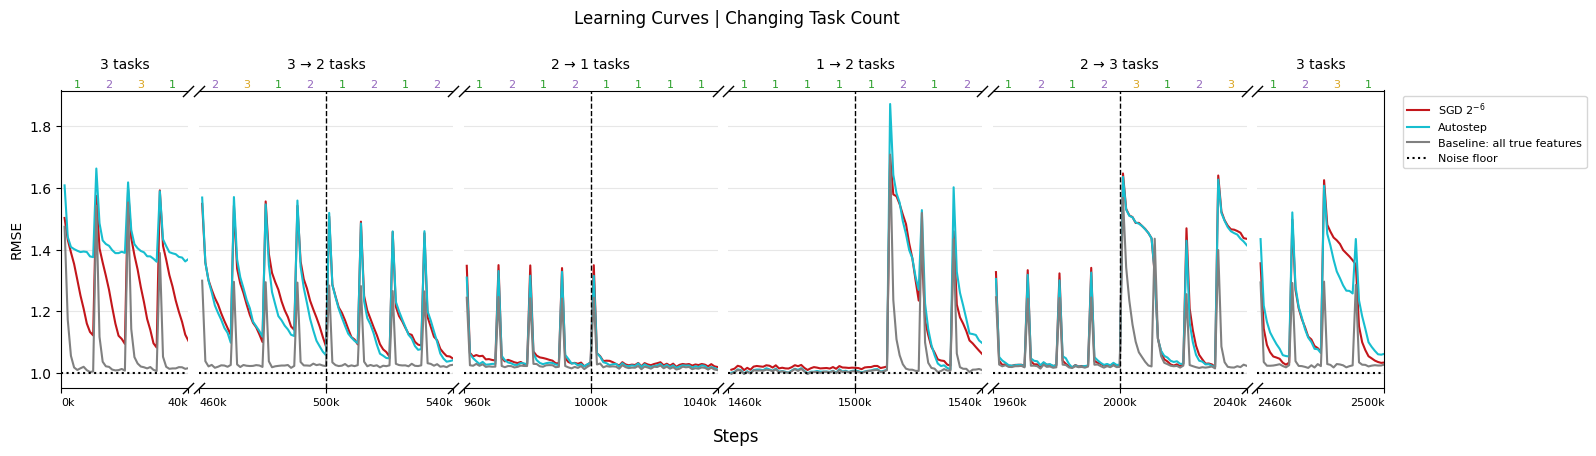

In [8]:
plot_curves([best, n, n + 2], 'Learning Curves | Changing Task Count')

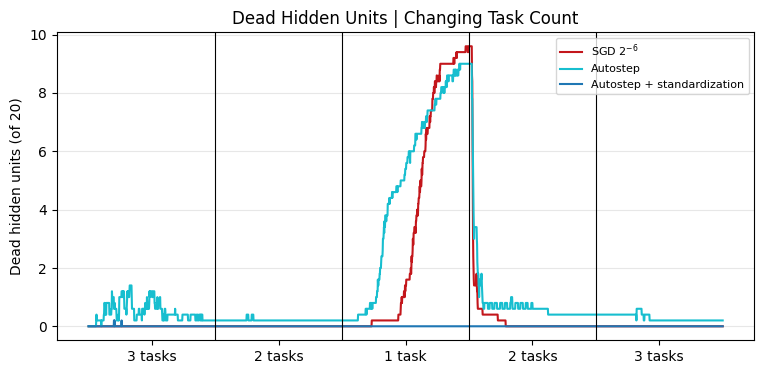

In [9]:
def zscore(a):
    return (a - a.mean(-1, keepdims=True)) / (a.std(-1, keepdims=True) + 1e-8)


START = ACTIVE.index(1) * PHASE_STEPS // WINDOW - 1  # last window before the 1-task phase


@jax.jit
def unit_stats(hidden):
    # hidden: (seed, window, unit, input + bias). Firing on the probe inputs: (seed, window, unit, probe).
    firing = (hidden @ jnp.append(PROBE, jnp.ones((len(PROBE), 1)), axis=1).T > 0).astype(jnp.float32)
    rate = firing.mean(-1)
    dead = jnp.sum((rate < .01) | (rate > .99), -1)
    before = zscore(firing[:, START])
    correlation = jnp.abs(jnp.einsum('swup,sup->swu', zscore(firing), before)) / len(PROBE)
    teacher_firing = jax.vmap(lambda s: teachers_for(s)[0].reshape(-1, N_INPUTS) @ PROBE.T > THRESHOLD)(jnp.arange(N_SEEDS))
    teacher = jnp.abs(jnp.einsum('sup,stp->sut', before, zscore(teacher_firing.astype(jnp.float32)))).argmax(-1) // WIDTH
    return dead, correlation, teacher


def phase_axis(ax):
    for boundary in range(PHASE_STEPS, STEPS, PHASE_STEPS):
        ax.axvline(boundary, color='black', lw=.8)
    ax.set_xticks(np.arange(len(ACTIVE)) * PHASE_STEPS + PHASE_STEPS / 2, [f'{a} task' + 's' * (a > 1) for a in ACTIVE])
    ax.grid(True, axis='y', alpha=.3)


stats = {i: [np.asarray(a) for a in unit_stats(hidden[i])] for i in (best, n, n + 1)}
fig, ax = plt.subplots(figsize=(9, 4))
for i, (dead, _, _) in stats.items():
    ax.plot(x, dead.mean(0), color=COLORS[i], label=LABELS[i])
phase_axis(ax)
ax.set_ylabel(f'Dead hidden units (of {N_HIDDEN})')
ax.legend(fontsize=8)
ax.set_title('Dead Hidden Units | Changing Task Count')
plt.show()

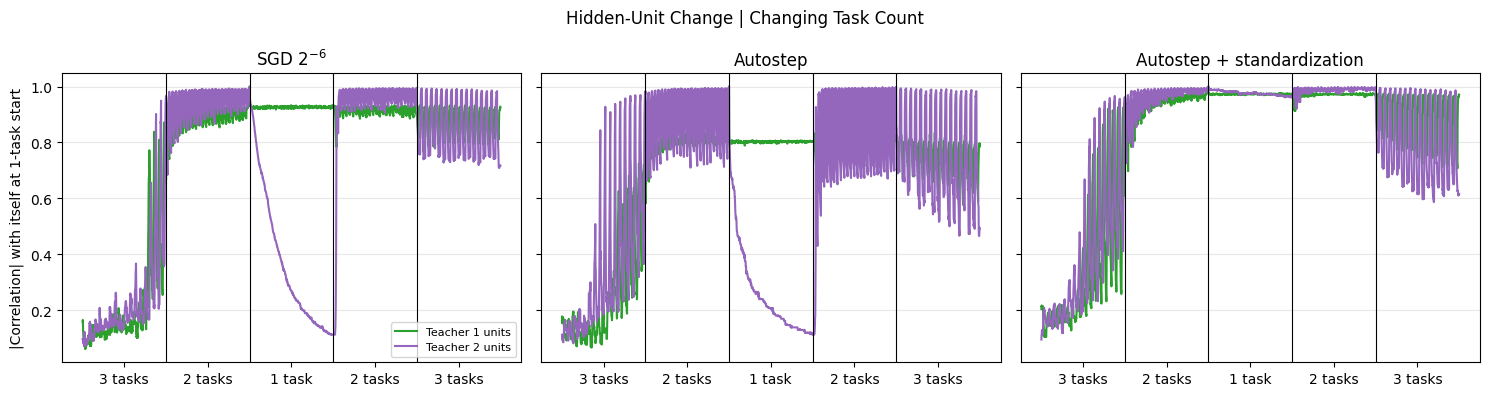

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (i, (_, correlation, teacher)) in zip(axes, stats.items()):
    correlation = correlation.transpose(1, 0, 2)  # (window, seed, unit)
    for t in range(2):
        ax.plot(x, np.median(correlation[:, teacher == t], axis=1), color=TASK_COLORS[t], label=f'Teacher {t + 1} units')
    phase_axis(ax)
    ax.set_title(LABELS[i])
axes[0].set_ylabel('|Correlation| with itself at 1-task start')
axes[0].legend(fontsize=8)
fig.suptitle('Hidden-Unit Change | Changing Task Count')
fig.tight_layout()
plt.show()

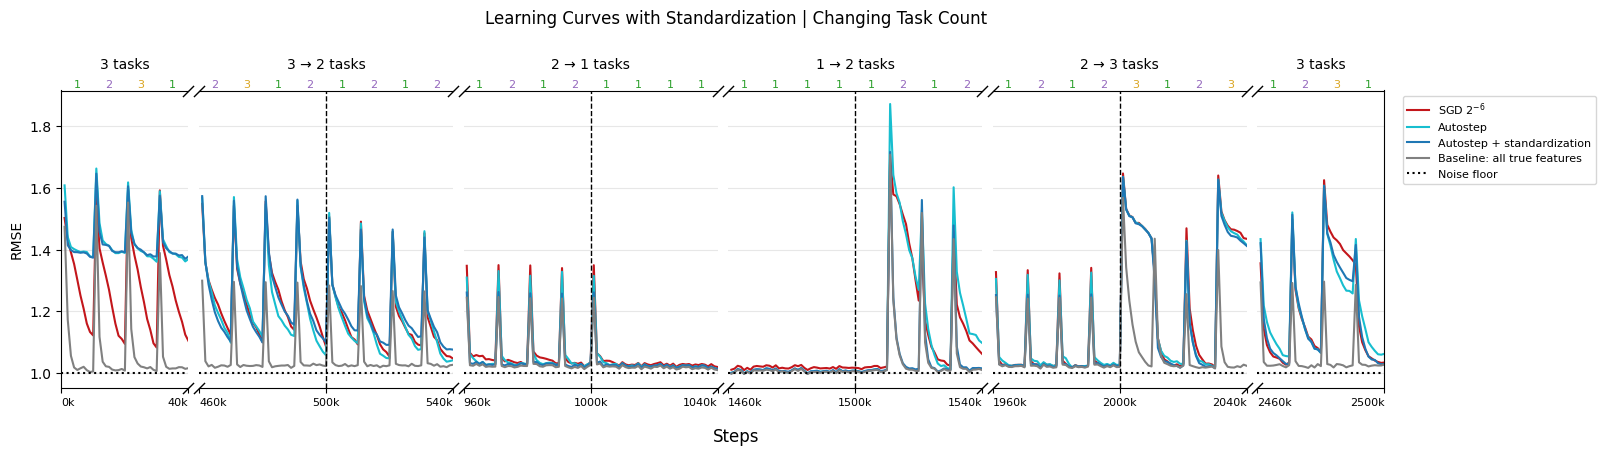

In [11]:
plot_curves([best, n, n + 1, n + 2], 'Learning Curves with Standardization | Changing Task Count')